N=1/3 at t=33.517s (dur=33.517s)
N=2/3 at t=69.876s (dur=36.359s)
N=3/3 at t=106.343s (dur=36.467s)


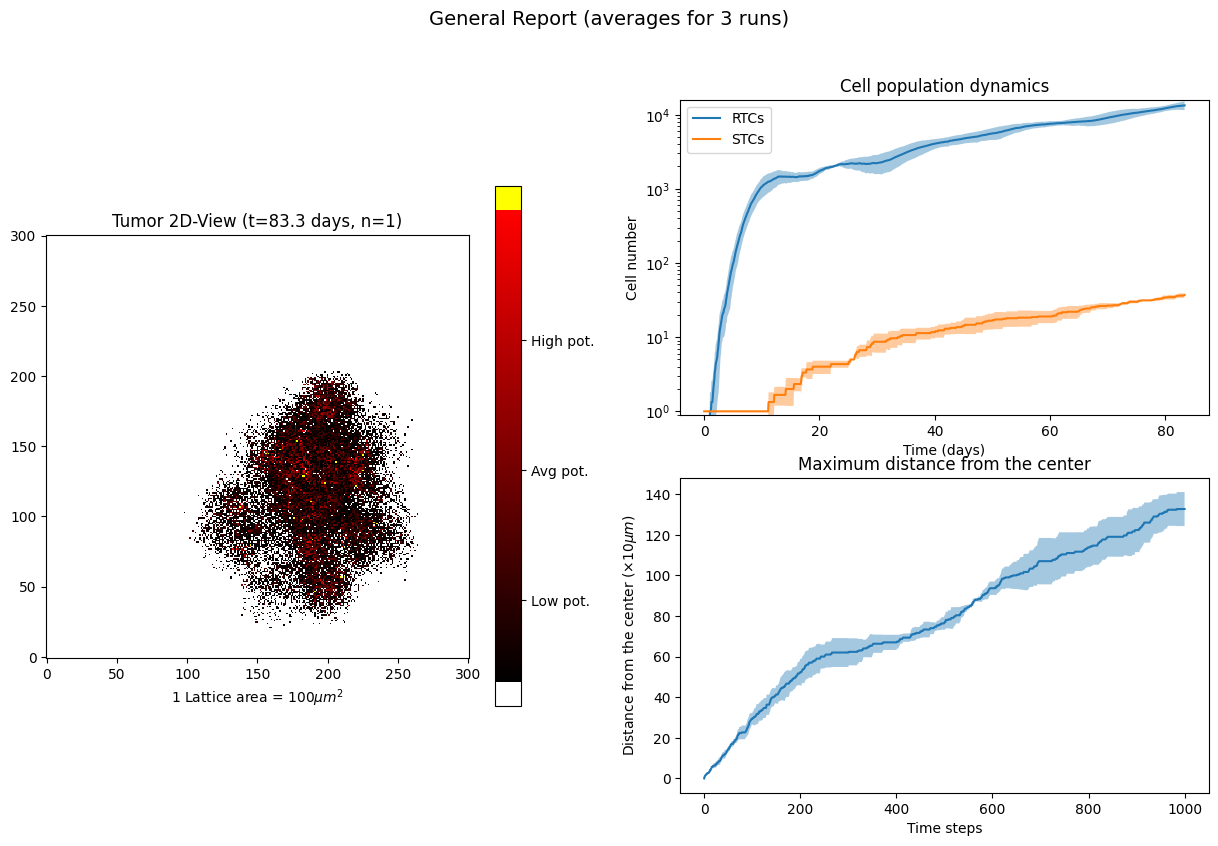

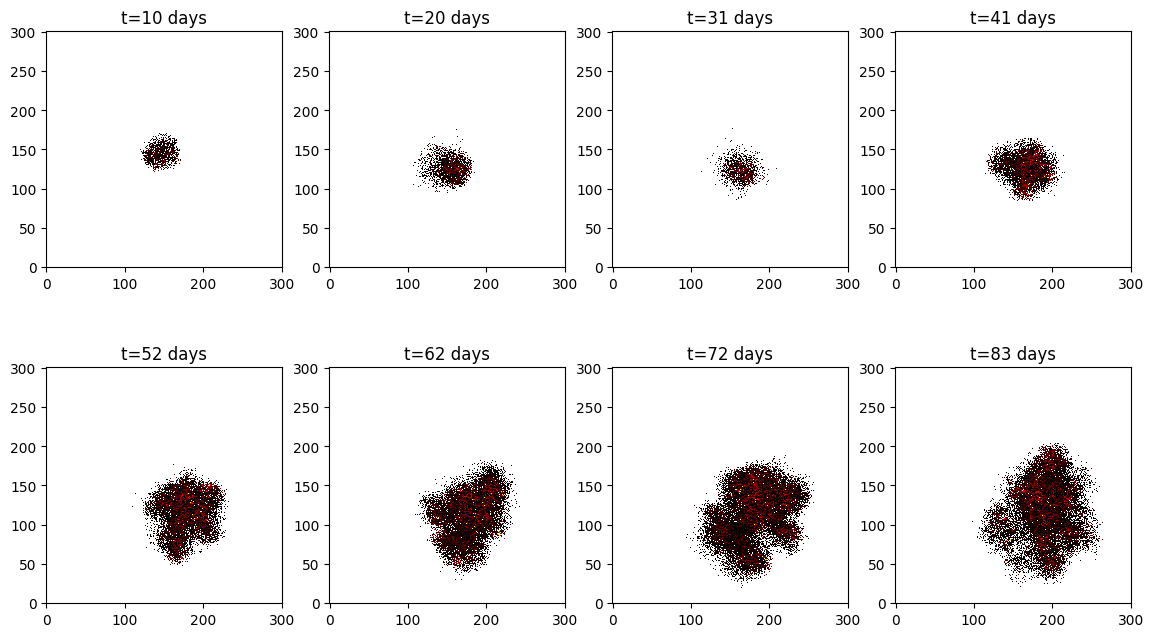

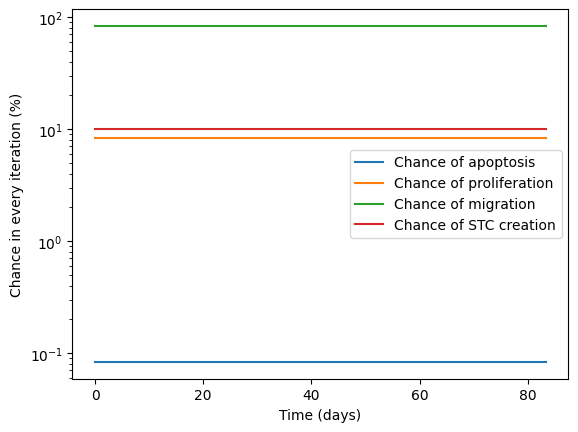

========================== SIMPLE REPORT ========================== 

Code Vers.: 19     N# simulations: 3    Date: 2026-09-23 16:01:04

System information (runtime)
Total:106.343  Average:35.448  Max:36.467  Min:33.517   STD:1.366 

Model information:
Time steps:1000 Step length:0.083 Time spam (days):83.333
CCT (hours):24  Proliferation potential:11  Migration potential:1

Probability information
Death:0.00 Proliferation:0.08 Migration:0.83 Stem generation:0.10

General results: (at t = 83.33333333333333 )
N:0 STC:40 RTC:15700 Max Radius:124
N:1 STC:36 RTC:12955 Max Radius:144
N:2 STC:35 RTC:11297 Max Radius:130

Average results: (at t = 83.33333333333333 )
STC:37.000 +-2.160   (Max:40.000, Min:35.000)
RTC:13317.333 +-1815.685   (Max:15700.000, Min:11297.000)
Max Radius:132.667 +- 8.380  (Max:144.000, Min:124.000)



In [1]:
"""
This code is the full python model companion to the paper "Cellular-automaton model for tumor growth dynamics: virtualization of different scenarios"
by Carlos A. Valentim, Jose A. Rabi, and Sergio A. David (University of Sao Paulo, Brazil). Submitted to the journal Computers in Biology and Medicine
(Elsevier) on October 27, 2022 and currently under review.
[[THIS FILE WILL BE UPDATED WITH A LINK IF THE PAPER IS ACCEPTED]]

This code is under a GNU AGPLv3 license.

The model is a Stocastic Cellular Automaton that can describe several tumor scenarios. Main characteristics:
- Basic agent-based model with 2D Moore neighborhood
- Agent/cell states include stem and tumor cells with different proliferation potentials.
- Agente behaviors include: Death OR Prolif OR Movemnt OR Quiescence.
- Implementation techniques: Random sweeping;  Expanding domain; Visualization with snapshots.
- On/Off sys_switches for plotting, printing, reporting and saving.
- Time-variable chances w/ plot at the end
"""

import numpy as np #science and math
import itertools #iterators
import matplotlib.pyplot as plt  #plot and viewing
from matplotlib.colors import LinearSegmentedColormap #colorbars
import matplotlib.gridspec as gridspec #help with subplot
import random #random chances (unitary)
from timeit import default_timer as timer #For measuring running time
from datetime import datetime #import date to show on reports
import pickle #for saving whole variables
import sys #for saving txt

def create_tumor(param_stem):
    """ From given param_stem creates and returns the tumor matrix, its size and its center"""
    tumor_n = 11 #Size of the initial tumor system:  squared ODD matrix
    tumor_center = tumor_n//2 #Center of the matrix / initial tumor cell
    tumor = np.zeros((tumor_n,tumor_n),dtype=int) # Create a matrix of empty spaces (zeros)
    tumor[tumor_center][tumor_center] = param_stem #param_stem # Puts a stem tumor cell in the middle of the matrix
    return tumor, tumor_n, tumor_center
def order_sweep(tumor_backup):
    """ Returns a random sweeping order to accesss cord (rows, columns) for tumor_backup matrix"""
    i,j = np.matrix.nonzero(tumor_backup[1:-1,1:-1]) #returns all coordinates i,j where there is a tumor cell
    cord = np.transpose([i,j])+1 #transpose to get an array of coordinates i,j for all cells
    order = np.arange(0,len(cord)) #create a vector going from 0 to N (number of cells)
    np.random.shuffle(order) #Randomly change the vector "order" (i.e. 0, 1,2.. -> 77, 34, ...)
    return cord, order #returns the coordinates indicating where there are cells and a random order to sweep them
def calc_chance(cord, order):
    """ Calculate order-sized arrays with random chances """
    cord_n = len(cord) #get number of tumor cells
    tumor_death = np.random.rand(cord_n); tumor_prolif = np.random.rand(cord_n);  tumor_migr = np.random.rand(cord_n); #calculate vectors of random chances for each ocasion and cell
    return tumor_death, tumor_prolif, tumor_migr #return chance arrays
def calc_free_spots(A,i,j):
    """Picks free neighbours of cell at i,j from matrix A and returns a random one as 1,i,j"""
    neighbors_order = neighbors_all[int(40319*random.random())] #ramdonly pick one of the 40319 possible combinations for checking neighbors
    for n in neighbors_order: #for every 1 of the 8 possible neighbors
        ii,jj = neighbors[n] #get coordinates
        if A[i+ii,j+jj] == 0: #check if it is empty
            neighbors_success[1], neighbors_success[2] = ii, jj #if yes get coordinates of the empty space
            return neighbors_success #return coordinates of the free spot
    return neighbors_fail #in case no free spots are found, return an indicative of crowded (spots[0]=0))
def calc_rad(i,j,radius,nc):
    """Calculates the radius between the most distant tumor cell at i,j and the center of the matrix nc"""
    dist = np.sqrt((nc-i)**2 + (nc-j)**2) #Calculate the distance
    if dist > radius: #If the distance is larger than previously largest distance
        return dist #Returns new distance as current radius
    else:
        return radius #Otherwise maintain the previous radius
def calc_pop(tumor_snap,param_stem):
    """Calculate the total, stem and tumor cells population from tumor matrix and given param_stem"""
    pop_stem = np.array([np.sum(tumor_snapshots[i]==param_stem) for i in range (0,t_max+1)]) #sum all stem cells at each t creating a vector
    pop_tot = np.array([np.sum(tumor_snapshots[i]>0) for i in range (0,t_max+1)]) #sum all cells at each t creating a vector
    pop_reg = pop_tot-pop_stem #create a vector for regular cells
    return pop_tot, pop_stem, pop_reg #return population vectors
def create_extension(tumor, n, nc, n_plus):
    """Extends the tumor matrix Tumor centered at nc with n columns/rows by a factor of nplus rows and columns"""
    #n_plus=(101-n)//2 #Arbitrary factor by which the domain will grow
    aux_B=np.zeros((n,n_plus),dtype=int) #Create an auxiliary zero matrix
    aux_C=np.zeros((n_plus,2*n_plus+n),dtype=int) #Create an extended auxiliary zero matrix
    n=n+2*n_plus #The tumor matrix size will increase by this factor
    nc=n//2 #Recalculating the new center
    tumor = np.concatenate((aux_B,tumor,aux_B),axis=1) #Concatenating empty sides
    tumor = np.concatenate((aux_C,tumor,aux_C),axis=0) #Concatenating empty matrices
    return tumor, n, nc
def calc_mean(aux_vector):
    """ Return mean and std from an input vector"""
    aux_mean = np.average (aux_vector, axis=0)
    aux_std = np.std(aux_vector, axis=0)
    return aux_mean, aux_std
def calc_index_representative(vect_pop_reg, pop_reg_mean, vect_pop_stem, pop_stem_mean, vect_rad, tumor_rad_mean):
    """Find the index of the most representative simulation run of the average values"""
    ste = (vect_pop_stem[:,-1]-pop_stem_mean[-1])**2/pop_stem_mean[-1]**2 #calc stem relative difference from mean (for every n)
    reg = (vect_pop_reg[:,-1]-pop_reg_mean[-1])**2/pop_reg_mean[-1]**2 #calc reg relative difference from mean (for every n)
    rad = (vect_rad[:,-1]-tumor_rad_mean[-1])**2/tumor_rad_mean[-1]**2 #calc maxrad relative difference from mean (for every n)
    k_rep = np.argmin(0.5*reg + 0.3*ste + 0.2*rad) #identifies the minimal error according to ponderation (50% stc, 30% rtc, 20% dispersion)
    return k_rep #return the index aka the n_run number of the most representative tumor
def main_ca(tumor, tumor_rad_new):
    """ Updates the tumor matrix of the CA and new radius after a time iteration """
    cord, order = order_sweep(tumor) #get the coordinates with tumor cells and a random sweep order
    tumor_death, tumor_prolif, tumor_migr = calc_chance(cord, order) #calculate arrays with random chances for each living cell
    for n in order: #for each element in random order
        i, j = cord[n] #get coordinate
        if (tumor[i][j]<param_stem and tumor_death[n]<=chance_death): #Checks for chance of death
            tumor[i][j]=0 #Make space if death occurs
        else: #In case death does not occur
            if tumor_prolif[n] <= chance_proliferation or tumor_migr[n] <= chance_migration: #in case any of the two behaviors happens
                spots = calc_free_spots(tumor,i,j) #Check if there are free adjacent spots
                if spots[0]==0: #if there are no adjacent spots
                    if tumor_prolif[n]<=chance_proliferation: #checks for chance of proliferation
                        if tumor[i][j] == param_stem: #if the cell is stem
                            if random.random()<=chance_stem: #check for chance of generating another stem
                                tumor[i+spots[1]][j+spots[2]] = param_stem #if yes create stem
                            else:
                                tumor[i+spots[1]][j+spots[2]] = param_reg #if no create regular cell
                        else: #if cell is not stem
                            tumor[i][j] -= 1 #decrease its replication potential
                            tumor[i+spots[1]][j+spots[2]] = tumor[i][j] #create identical daughter cell
                        tumor_rad_new = calc_rad(i+spots[1],j+spots[2],tumor_rad_new,tumor_center) #update maximum radius
                    else:
                        tumor[i+spots[1]][j+spots[2]] = tumor[i][j] #copy cell to adjacent random spot
                        tumor[i][j] = 0 #delete original cell
                        tumor_rad_new = calc_rad(i+spots[1],j+spots[2],tumor_rad_new,tumor_center) #update max radius
    return tumor, tumor_rad_new
def see_end():
    """General report / visualization - no input"""
    plt.style.use('default') #Plot style as default
    gs = gridspec.GridSpec(2,2) #Create a 2x2 grid for plots
    fig1 = plt.figure(figsize=(15,9)) #create a figure
    ax1 = fig1.add_subplot(gs[:,0]) #One big plot on the left
    ax2 = fig1.add_subplot(gs[0,1]) #Second plot on the right
    ax4 = fig1.add_subplot(gs[1,1]) #Third plot on the right
    fig1.suptitle('General Report (averages for '+str(sys_nruns)+' runs)',fontsize=14)    #Tumor spatial view
    cmap = LinearSegmentedColormap.from_list('name', ['black', 'red']) #Cmap for cells distinguishment
    cmap.set_under('white'); cmap.set_over('yellow') #Limits of colors
    tumor_2D = ax1.imshow(tumor_snapshots[t_max], interpolation='nearest', vmin=1, vmax=param_reg, cmap=cmap, origin='lower') #OPick the last spatial snap for plot
    ax1.set_title('Tumor 2D-View (t={:.1f} days, n={:d})'.format(t_max*dt,tumor_representative_index)) #Title
    ax1.set_xlabel(r'1 Lattice area = $100\mu m^2$') #Label
    cbar = fig1.colorbar(tumor_2D, ax=ax1, extend='both', extendrect='false', shrink=0.75, ticks=[0.75,0.25*param_reg,0.5*param_reg,0.75*param_reg,param_stem-0.75], orientation='vertical')
    cbar.ax.set_yticklabels(['Empty','Low pot.', 'Avg pot.', 'High pot.','STCs'])  # horizontal colorbar
    #Dynamic population view
    ax2.plot(t_vector*dt, pop_reg_mean, label='RTCs')
    ax2.fill_between(t_vector*dt, (pop_reg_mean-pop_reg_std), (pop_reg_mean+pop_reg_std), alpha=0.4)
    ax2.plot(t_vector*dt, pop_stem_mean, label='STCs')
    ax2.fill_between(t_vector*dt, (pop_stem_mean-pop_stem_std), (pop_stem_mean+pop_stem_std), alpha=0.4)
    ax2.set_ylim(0.9,)
    ax2.set_yscale('log')
    ax2.set_xlabel('Time (days)')
    ax2.set_ylabel('Cell number')
    ax2.set_title('Cell population dynamics')
    ax2.legend()
    #Tumor Radius
    ax4.fill_between(t_vector, (tumor_rad_mean-tumor_rad_std), (tumor_rad_mean+tumor_rad_std), alpha=0.4)
    ax4.plot(t_vector,tumor_rad_mean)
    ax4.set_xlabel('Time steps')
    ax4.set_ylabel(r'Distance from the center ($\times 10 \mu m$)')
    ax4.set_title('Maximum distance from the center')
    plt.show()
    return fig1
def see_partial():
    """General report / visualization - no input"""
    plt.style.use('default')
    gs = gridspec.GridSpec(2,2)
    fig1 = plt.figure(figsize=(15,9))#figsize=(18,11), dpi=80)
    ax1 = fig1.add_subplot(gs[:,0])
    ax2 = fig1.add_subplot(gs[0,1])
    ax4 = fig1.add_subplot(gs[1,1])
    fig1.suptitle('General Report (n='+str(k)+')',fontsize=14)
    #Tumor spatial view
    cmap = LinearSegmentedColormap.from_list('name', ['black', 'red'])
    cmap.set_under('white'); cmap.set_over('yellow')
    tumor_2D = ax1.imshow(tumor, interpolation='nearest', vmin=1, vmax=param_reg, cmap=cmap, origin='lower')
    ax1.set_title('Tumor 2D-View (t=%i days)' %(t_max*dt))
    ax1.set_xlabel(r'1 Lattice area = $100\mu m^2$')
    cbar = fig1.colorbar(tumor_2D, ax=ax1, extend='both', extendrect='false', shrink=0.75, ticks=[0.75,0.25*param_reg,0.5*param_reg,0.75*param_reg,param_stem-0.75], orientation='vertical')
    cbar.ax.set_yticklabels(['Empty','Low pot.', 'Avg pot.', 'High pot.','STCs'])  # horizontal colorbar
    #Dynamic population view
    ax2.plot(t_vector*dt, pop_reg, label='RTCs')
    ax2.plot(t_vector*dt, pop_stem, label='STCs')
    ax2.set_ylim(0.9,)
    ax2.set_yscale('log')
    ax2.set_xlabel('Time (days)')
    ax2.set_ylabel('Cell number')
    ax2.set_title('Cell population dynamics')
    ax2.legend()
    #Tumor Radius
    ax4.plot(t_vector,tumor_rad)
    ax4.set_xlabel('Time steps')
    ax4.set_ylabel(r'Distance from the center ($\times 10 \mu m$)')
    ax4.set_title('Maximum distance from the center')
    plt.show()
def see_snapshots():
    """ Exhibits 8 snapshots of tumor evolution - no input"""
    stampstep = t_max//8 #get 8 equally-spaced snaps
    aux_max = len(tumor_snapshots[-1])
    plt.style.use('default')
    fig2, ax = plt.subplots(nrows=2, ncols=4, figsize=(14,8))
    cmap = LinearSegmentedColormap.from_list('name', ['black', 'red'])
    cmap.set_under('white'); cmap.set_over('yellow')
    for k in range(1,9): #axs.flat[k] gets each subplot k in order and equally spaced acacording to nrows, ncols
        aux_tumor = tumor_snapshots[k*stampstep].copy() #copy the tumor evolution of all snapshots
        aux_n = len(aux_tumor); aux_nc = aux_n//2 #get the matrix size of the final tumor
        if aux_n < aux_max: #for all sizes smaller than the biggest tumor matrix
            aux_tumor,aux_n,aux_nc = create_extension(aux_tumor, aux_n, aux_nc, (aux_max-aux_n)//2)  #extend tumor matrices to match the maximum size
        ax.flat[k-1].imshow(aux_tumor, interpolation='nearest', vmin=1, vmax=param_reg, cmap=cmap, origin='lower') #plot
        ax.flat[k-1].set_title('t=%i days' %(k*stampstep*dt)) #Showing a timestamp in days for each snapshot
    plt.show()
    return fig2
def report_general():
    """ Prints on the screen a small report with crucial details and outputs of the simulation """
    print('========================== SIMPLE REPORT ========================== \n')
    print('Code Vers.:',ver,'    N# simulations:',sys_nruns,'   Date:',datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
    print('\nSystem information (runtime)')
    print('Total:{:.3f}  Average:{:.3f}  Max:{:.3f}  Min:{:.3f}   STD:{:.3f} '.format(sys_nruns*np.average(sys_t_run),np.average(sys_t_run),np.max(sys_t_run),np.min(sys_t_run),np.std(sys_t_run)))
    print('\nModel information:')
    print('Time steps:{:d} Step length:{:.3f} Time spam (days):{:.3f}'.format(t_max,dt,dt*t_max))
    print('CCT (hours):{:d}  Proliferation potential:{:.0f}  Migration potential:{:.0f}'.format(param_cct, param_reg, param_potm))
    print('\nProbability information')
    print('Death:{:.2f} Proliferation:{:.2f} Migration:{:.2f} Stem generation:{:.2f}'.format(chance_death,chance_proliferation,chance_migration,chance_stem))
    print('\nGeneral results: (at t =',t_max*dt,')')
    for kk in range(0,sys_nruns):
        print('N:{:d} STC:{:d} RTC:{:d} Max Radius:{:d}'.format(kk, vect_pop_stem[kk,t_max], vect_pop_reg[kk,t_max], vect_rad[kk, t_max]))
    print('\nAverage results: (at t =',t_max*dt,')')
    print('STC:{:.3f} +-{:.3f}   (Max:{:.3f}, Min:{:.3f})'.format(pop_stem_mean[t_max],pop_stem_std[t_max],max(vect_pop_stem[:,t_max]),min(vect_pop_stem[:,t_max])))
    print('RTC:{:.3f} +-{:.3f}   (Max:{:.3f}, Min:{:.3f})'.format(pop_reg_mean[t_max],pop_reg_std[t_max],max(vect_pop_reg[:,t_max]),min(vect_pop_reg[:,t_max])))
    print('Max Radius:{:.3f} +- {:.3f}  (Max:{:.3f}, Min:{:.3f})'.format(tumor_rad_mean[t_max], tumor_rad_std[t_max], max(vect_rad[:,t_max]), min(vect_rad[:,t_max])))
def save_files():
    """Saves plots and report of the simulation. Also saves variables if desired"""
    date_string = datetime.now() #get current date
    date_string = date_string.strftime("_%Y-%m-%d_%H-%M") #convert to string name
    filename = 'V'+ver+'_n'+str(sys_nruns)+'_tmax'+str(t_max)+date_string #create filename
    original_stdout = sys.stdout #make a copy of original sys.stdout
    with open('Data/'+filename+'.txt',"w") as file: #open a txt file with filename data
        sys.stdout = file #change the output of the console to this file
        report_general() #run report print function again, but this time to the file
        sys.stdout = original_stdout #return stdout as before
    fig_general.savefig('Data/'+filename+'_overview.pdf', format = 'pdf') #saves general report fig to  a file
    fig_evolution.savefig('Data/'+filename+'_evolution.pdf', format = 'pdf') # saves tumor evolution fig to another file
    fig_chances.savefig('Data/'+filename+'_chances.pdf', format = 'pdf') # saves tumor evolution fig to another file
    if sys_save == True: #if switch save is on:
        var_parameters = [sys_nruns,t_max, dt,param_cct, param_reg, param_stem, param_potm,chance_death, chance_proliferation, chance_migration, chance_stem]
        with open('Data/'+filename+'_param.dat', 'wb') as f: #create dat file
            pickle.dump(var_parameters, f)
        with open('Data/'+filename+'_data.dat', 'wb') as f: #create dat file
            pickle.dump([vect_tumor_snapshots, vect_rad], f) #store vect_tumor_snapshots (from which everything can be derived later)
def see_chances():
    """ Returns figure w/ simple plot of time-variable changes - No input"""
    plt.style.use('default')
    fig, ax = plt.subplots()
    ax.plot(t_vector*dt, vect_deat*100, label='Chance of apoptosis')
    ax.plot(t_vector*dt, vect_prol*100, label='Chance of proliferation')
    ax.plot(t_vector*dt, vect_potm*100, label='Chance of migration')
    ax.plot(t_vector*dt, vect_stem*100, label='Chance of STC creation')
    ax.set_xlabel('Time (days)')
    ax.set_ylabel('Chance in every iteration (%)')
    ax.set_yscale('log')
    ax.legend()
    plt.show()
    return fig

"Time parameters"
ver = '19' #Version
t_max=1000 #Total ammount of steps dt
dt = 1/12 # Time step size (fraction of a day)
"Model parameters"
param_cct = 24 #cell cicle time (hours)
param_reg = 11 #proliferation potential of regular tumor cell (number of divisions unitl death + 1)
param_stem = param_reg+1 #stem cells have superior proliferation potential (and dont die)
param_potm = 1 #migration potential in cell width  per day
vect_deat,vect_prol,vect_potm,vect_stem = (np.empty(t_max+1) for i in range(4)) #create empty vectors for time-variable chances
vect_deat[:round(0.5*t_max)]=0.01*dt; vect_deat[round(0.5*t_max):]=0.01*dt #chance of death changing w/ time
vect_prol[:] =  (24/param_cct*dt) # Chance of proliferation
vect_potm[:round(0.4*t_max)] = 10*dt; vect_potm[round(0.4*t_max):] = 10*dt; #Chance of migration changing w/ time
vect_stem[:] = 0.1 #Probability of creating a daughter stem cell
"System configuration"
sys_nruns =3; sys_t_run = [] #Number of random runs and vector for runtimes
sys_visu_partial=False; sys_visu_end=True; sys_print=True; sys_report=False; sys_save=False; #Control of plot/print generation and file saving
vect_pop_stem = np.empty((sys_nruns,t_max+1), dtype=int)  #creation of empty vectors for populations and radius
vect_pop_reg = np.empty((sys_nruns,t_max+1), dtype=int)
vect_rad = np.empty((sys_nruns,t_max+1), dtype=int)
vect_tumor_snapshots = [None]*(sys_nruns) #Creating an empty list for receiving all snapshots
neighbors = np.array([[-1, -1], [-1, 0], [-1, 1], [0, -1], [0, 1], [1, -1], [1, 0], [1, 1]],dtype=int) #Coordinates for all 8 possible neighbors
neighbors_success = np.array([0, 0, 0], dtype=int) #returning vector of check_spots when a free spot is found
neighbors_fail = np.array([1, 0, 0], dtype=int) #returning vector of check_spots when no free spots are found
neighbors_permutation = list(itertools.permutations(np.arange(0,8, dtype=int))) #all possible combinations of 0-7
neighbors_all = np.array(neighbors_permutation[:]) #transforming tuple into an array
np.random.seed(6) #use only when trying to control results for verification purposes
random.seed(6)

"System run"
for k in range (0,sys_nruns): #Loop for system runs
    "System initialization"
    sys_t_start = timer() # Register simulation start time
    t = 0 #Start initial time step
    t_count = 0 #count for printing progress bar
    t_vector = np.array(range(t_max+1)) # Create time vector
    tumor, tumor_n, tumor_center = create_tumor(param_stem) #Create tumor matrix
    tumor_snapshots = [None]*(t_max+1); tumor_snapshots[0] = tumor.copy() #Creating empty list to receive snapshots of tumor 2D evolution
    tumor_rad = np.empty(t_max+1); tumor_rad[0] = 0 #Create radius vector and initialize vector = 0
    "Time loop"
    for t in range(1,t_max+1): #Loop for every time step until t_max
        chance_death, chance_proliferation, chance_migration, chance_stem = vect_deat[t],vect_prol[t],vect_potm[t],vect_stem[t]  #Probabilities inside the loop (i.e.they may change with t)
        tumor, tumor_rad[t] = main_ca(tumor, tumor_rad[t-1]) #Run the main CA process for the tumor matrix, get updated tumor matrix and radius
        if tumor_rad[t] >= tumor_center-1:  #If the radius is getting close to the domain border
            tumor, tumor_n, tumor_center = create_extension(tumor, tumor_n, tumor_center, 5) #Expand
        tumor_snapshots[t]=tumor.copy() #Copy tumor matrix at this time instant
        if t%((t_max)//10)==0: # for every 10% of t
            t_count += 10
            print('\r Progress = [%d %%] \r'%t_count, end="") #Print %progress 10-10 for each iteration
    "Population dynamics"
    pop_tot, pop_stem, pop_reg = calc_pop(tumor,param_stem) #count population
    vect_pop_stem[k] = pop_stem; vect_pop_reg[k] = pop_reg; vect_rad[k] = tumor_rad #save pop and radius vectors
    vect_tumor_snapshots[k] = tumor_snapshots #save snapshots for this run
    "System calculations"
    sys_t_end = timer() #Get the end time for this sytem run
    sys_t_run.append(sys_t_end - sys_t_start) #Append to the runtime vector the current runtime
    if sys_visu_partial==True: see_partial() #Check if user wants to see partial reports
    print('N={:d}/{:d} at t={:.3f}s (dur={:.3f}s)'.format(k+1, sys_nruns, np.sum(sys_t_run), sys_t_run[k])) #Print the status after each iteration ends

"Average / representative dynamics"
pop_stem_mean, pop_stem_std = calc_mean(vect_pop_stem) #calc the mean stem time series
pop_reg_mean, pop_reg_std = calc_mean(vect_pop_reg) #calc the mean reg time series
tumor_rad_mean, tumor_rad_std = calc_mean(vect_rad) #calc the mean radius time series
tumor_representative_index = calc_index_representative(vect_pop_reg, pop_reg_mean, vect_pop_stem, pop_stem_mean, vect_rad, tumor_rad_mean)
tumor_snapshots = vect_tumor_snapshots[tumor_representative_index] #Find and save the snapshots that are closer to the mean


"Visualization"
if sys_visu_end==True:
    fig_general = see_end() #General report of last run
    fig_evolution = see_snapshots() #Tumor snapshots of last run
    fig_chances = see_chances() #Chances changing with time

"System saving / storing / printing"
if sys_print == True: report_general() #If print switch is on: print simple report
if sys_report == True: save_files() #If save switch is on: save report files

print('\007') #Sound alert when the simulation is finished.